YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed
c:\Projects\KalAnalysis\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - loss: 0.1522 - val_loss: 0.0459
Epoch 2/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 0.0069 - val_loss: 0.0284
Epoch 3/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 0.0043 - val_loss: 0.0194
Epoch 4/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - loss: 0.0043 - val_loss: 0.0152
Epoch 5/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - loss: 0.0040 - val_loss: 0.0110
Epoch 6/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - loss: 0.0037 - val_loss: 0.0094
Epoch 7/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step - loss: 0.0036 - val_loss: 0.0110
Epoch 8/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - loss: 0.0037 - val_loss: 0.0071
Epoch 9/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - loss: 0.0039 - val_loss: 0.0134
Epoch 10/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - loss: 0.0036 - val_loss: 0.0080
Epoch 11/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - loss: 0.0036 - val_loss: 0.0089
Epoch 12/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step - loss: 0.0

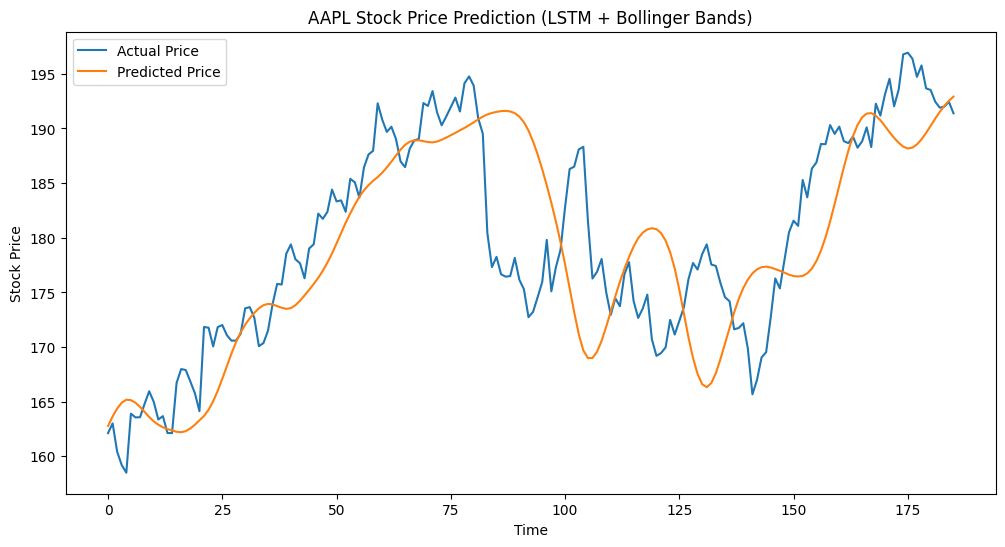

Test Mean Squared Error: 43.1943


In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Step 1: Download stock data
ticker = "AAPL"  # Choose your stock
data = yf.download(ticker, start="2020-01-01", end="2024-01-01")

# Step 2: Calculate Bollinger Bands
data['MiddleBand'] = data['Close'].rolling(window=20).mean()
data['StdDev'] = data['Close'].rolling(window=20).std()
data['UpperBand'] = data['MiddleBand'] + (2 * data['StdDev'])
data['LowerBand'] = data['MiddleBand'] - (2 * data['StdDev'])

# Step 3: Prepare dataset
data = data[['Close', 'MiddleBand', 'UpperBand', 'LowerBand']].dropna()

# Scale features
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# Step 4: Create sequences for LSTM
X = []
y = []

sequence_length = 60  # past 60 days

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i, 1:])  # Only Bollinger Bands
    y.append(scaled_data[i, 0])  # Closing price

X, y = np.array(X), np.array(y)

# Step 5: Train/test split
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Step 6: Build the LSTM model
model = Sequential()
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(LSTM(units=50))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mean_squared_error')

# Step 7: Train the model
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test), verbose=1)

# Step 8: Make predictions
predicted = model.predict(X_test)

# Inverse scale
close_scaler = MinMaxScaler()
close_scaler.min_, close_scaler.scale_ = scaler.min_[0], scaler.scale_[0]
predicted_prices = close_scaler.inverse_transform(predicted.reshape(-1,1))
real_prices = close_scaler.inverse_transform(y_test.reshape(-1,1))

# Step 9: Plot results
plt.figure(figsize=(12,6))
plt.plot(real_prices, label='Actual Price')
plt.plot(predicted_prices, label='Predicted Price')
plt.title(f"{ticker} Stock Price Prediction (LSTM + Bollinger Bands)")
plt.xlabel("Time")
plt.ylabel("Stock Price")
plt.legend()
plt.show()

# Step 10: Final Score
mse = np.mean((real_prices - predicted_prices)**2)
print(f"Test Mean Squared Error: {mse:.4f}")
